# Deep-dive Stage 3/5 -- optimizer x batch size

Part 3 of 5. Loads Stages 1-2's winners from the checkpoint, runs the optimizer x
batch-size grid -- {Adam, SGD} x {32, 64} -- on top of them, and writes an updated
`checkpoint.json` for Stage 4.


In [1]:
# ============================================================
# 1. CONFIG -- EDIT THESE FOR YOUR KAGGLE NOTEBOOK
# ============================================================
from pathlib import Path
import json as _json

# --- INPUTS: attach BOTH datasets to this notebook (Add Input -> Datasets, twice) --
# the plain patient-level split AND the augmented one -- needed again in every stage's
# notebook, since each stage re-trains from scratch.
SPLIT_ROOT_ORIGINAL = Path("/kaggle/input/datasets/gokulkrishnabr/segmented-zenodo/train test vali zenodo")
SPLIT_ROOT_AUGMENTED = Path("/kaggle/input/datasets/gokulkrishnabr/augmented-zenodo/augmented_dataset")
for _root in (SPLIT_ROOT_ORIGINAL, SPLIT_ROOT_AUGMENTED):
    for _s in ("train", "val", "test"):
        assert (_root / _s).is_dir(), f"{_root / _s} not found -- fix the paths above."

DATA_VARIANTS = {"original": SPLIT_ROOT_ORIGINAL, "augmented": SPLIT_ROOT_AUGMENTED}
LOSS_VARIANTS = {"unweighted": False, "weighted": True}

OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_OUTPUT = OUTPUT_DIR / "checkpoint.json"

# --- CHECKPOINT: attach the PREVIOUS stage's Output as a third dataset input, then
# fix this path to point at its checkpoint.json.
CHECKPOINT_INPUT = Path("/kaggle/input/datasets/gokulkrishnabr/json-stage-2/checkpoint.json")
assert CHECKPOINT_INPUT.is_file(), (
    f"{CHECKPOINT_INPUT} not found -- attach stage2's Output dataset and fix this path.")
_ckpt = _json.loads(CHECKPOINT_INPUT.read_text())
print("Loaded checkpoint from stage2:")
for _k, _v in _ckpt.items():
    print(f"  {_k} = {_v}")

BACKBONE_KEY = _ckpt["BACKBONE_KEY"]
BEST_PHASE2_LR = _ckpt["BEST_PHASE2_LR"]

BEST_DATA_VARIANT = _ckpt["BEST_DATA_VARIANT"]
BEST_LOSS_VARIANT = _ckpt["BEST_LOSS_VARIANT"]
BEST_DROPOUT = _ckpt["BEST_DROPOUT"]
BEST_WEIGHT_DECAY = _ckpt["BEST_WEIGHT_DECAY"]

IMG_SIZE = 224
BATCH_SIZE = 32
PHASE1_LR = 1e-3
RANDOM_SEED = 42

GRID_PHASE1_EPOCHS = 8
GRID_PHASE2_EPOCHS = 12
GRID_EARLY_STOP_PATIENCE = 4

USE_RUNTIME_AUGMENTATION = True
LABEL_SMOOTHING = 0.1
REDUCE_LR_FACTOR = 0.5
REDUCE_LR_PATIENCE = 3

BACKBONES = {
    "mobilenetv2": dict(title="MobileNetV2", keras_class="MobileNetV2",
                         module="keras.applications.mobilenet_v2", needs_manual_preprocess=True),
    "mobilenetv3small": dict(title="MobileNetV3-Small", keras_class="MobileNetV3Small",
                              module="keras.applications.mobilenet_v3", needs_manual_preprocess=False),
    "efficientnetb0": dict(title="EfficientNetB0", keras_class="EfficientNetB0",
                            module="keras.applications.efficientnet", needs_manual_preprocess=False),
    "efficientnetv2b0": dict(title="EfficientNetV2B0", keras_class="EfficientNetV2B0",
                              module="keras.applications.efficientnet_v2", needs_manual_preprocess=False),
}

OPTIMIZERS = ["adam", "sgd"]
BATCH_SIZES_GRID = [32, 64]

assert BACKBONE_KEY in BACKBONES, f"BACKBONE_KEY must be one of {list(BACKBONES)}"
BB = BACKBONES[BACKBONE_KEY]
print("\nBackbone            :", BB["title"])
print("Best Phase-2 LR      :", BEST_PHASE2_LR)
print("Output folder        :", OUTPUT_DIR)

print("Data/loss winner:", BEST_DATA_VARIANT, "/", BEST_LOSS_VARIANT)
print("Regularization winner: dropout=", BEST_DROPOUT, " weight_decay=", BEST_WEIGHT_DECAY)


Loaded checkpoint from stage2:
  BACKBONE_KEY = efficientnetb0
  BEST_PHASE2_LR = 0.0001
  BEST_DATA_VARIANT = augmented
  BEST_LOSS_VARIANT = weighted
  BEST_DROPOUT = 0.5
  BEST_WEIGHT_DECAY = 0.0

Backbone            : EfficientNetB0
Best Phase-2 LR      : 0.0001
Output folder        : /kaggle/working
Data/loss winner: augmented / weighted
Regularization winner: dropout= 0.5  weight_decay= 0.0


In [2]:
# ============================================================
# 2. IMPORTS + HELPERS (dataset builder, class-weight helper, model/optimizer builders,
#    eval, and a reusable curve-plotting helper for every tuning stage)
# ============================================================
import time
import gc
import json as _json
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow:", tf.__version__, " Keras:", keras.__version__)
tf.random.set_seed(RANDOM_SEED)

_backbone_module = importlib.import_module(BB["module"])
BACKBONE_CLASS = getattr(keras.applications, BB["keras_class"])
if BB["needs_manual_preprocess"]:
    _preprocess_input = getattr(_backbone_module, "preprocess_input")
    def preprocess(x, y):
        return _preprocess_input(x), y
else:
    def preprocess(x, y):
        return x, y   # this backbone's preprocessing is built in (include_preprocessing=True)

# --- Light, clinically-safe runtime augmentation -- applied to the TRAIN split only,
# on every run below, regardless of which Stage-1 data variant is in use. This is a
# separate, additional overfitting countermeasure from the offline OCA-oversampling
# done by the augmentation notebook (which only changes the "augmented" data variant):
# this one runs on-the-fly, on EVERY training image of EITHER variant, so it can't bias
# the Stage-1 original-vs-augmented comparison (both get it identically). Only the same
# safe transform families used by the offline augmentation notebook are used here --
# no vertical flip, no hue shift, no heavy distortion -- since those can misrepresent a
# lesion clinically.
_runtime_augmenter = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.04),     # ~+-15 degrees
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomContrast(0.1),
], name="runtime_augmentation")


def build_datasets(split_root, batch_size=None, augment_train=None):
    '''Loads train/val/test folder-per-class datasets from split_root, returns the
    preprocessed tf.data pipelines plus the raw (unbatched-friendly) train dataset used
    for computing class weights. batch_size defaults to the global BATCH_SIZE, but stage
    3 (optimizer x batch size) overrides it per cell. augment_train defaults to the
    global USE_RUNTIME_AUGMENTATION flag; val/test are NEVER augmented.'''
    bs = batch_size or BATCH_SIZE
    do_augment = USE_RUNTIME_AUGMENTATION if augment_train is None else augment_train
    train_raw = keras.utils.image_dataset_from_directory(
        split_root / "train", image_size=(IMG_SIZE, IMG_SIZE), batch_size=bs,
        label_mode="categorical", shuffle=True, seed=RANDOM_SEED)
    val_raw = keras.utils.image_dataset_from_directory(
        split_root / "val", image_size=(IMG_SIZE, IMG_SIZE), batch_size=bs,
        label_mode="categorical", shuffle=False)
    test_raw = keras.utils.image_dataset_from_directory(
        split_root / "test", image_size=(IMG_SIZE, IMG_SIZE), batch_size=bs,
        label_mode="categorical", shuffle=False)
    class_names = train_raw.class_names
    assert val_raw.class_names == class_names and test_raw.class_names == class_names, (
        f"Class folder names differ between train/val/test under {split_root}")
    if do_augment:
        train_ds = train_raw.map(lambda x, y: (_runtime_augmenter(x, training=True), y)).map(
            preprocess).prefetch(tf.data.AUTOTUNE)
    else:
        train_ds = train_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)
    val_ds = val_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)
    test_ds = test_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)
    return train_ds, val_ds, test_ds, train_raw, class_names


def class_weight_for(train_raw, n_classes, weighted):
    if not weighted:
        return None
    labels = np.array([int(tf.argmax(y).numpy()) for _, y in train_raw.unbatch()])
    w = compute_class_weight("balanced", classes=np.arange(n_classes), y=labels)
    return {i: v for i, v in enumerate(w)}


def make_optimizer(lr, weight_decay, optimizer_name):
    '''Decoupled weight decay via Keras 3's built-in `weight_decay` kwarg -- 0.0 is a
    valid value and simply disables it, so the same call works for every grid cell.'''
    if optimizer_name == "adam":
        return keras.optimizers.Adam(lr, weight_decay=weight_decay)
    if optimizer_name == "sgd":
        return keras.optimizers.SGD(lr, momentum=0.9, weight_decay=weight_decay)
    if optimizer_name == "rmsprop":
        return keras.optimizers.RMSprop(lr, weight_decay=weight_decay)
    raise ValueError(f"Unknown optimizer_name: {optimizer_name!r}")


def build_fresh_model(n_classes, dropout_rate=0.3, head_arch="plain"):
    '''A brand-new model with fresh ImageNet weights -- called once per grid cell so no
    fine-tuning from a previous combo leaks into the next one. head_arch controls the
    classification head on top of the pooled backbone features:
      "plain"           -- dropout -> dense(n_classes)                 (Stage A's head)
      "wide_relu"       -- dense(128, relu) -> dropout -> dense(n_classes)
      "wide_leaky_relu" -- dense(128) -> LeakyReLU(0.1) -> dropout -> dense(n_classes)
    '''
    base_model = BACKBONE_CLASS(
        include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    base_model.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    features = base_model(inputs, training=False)
    if head_arch == "plain":
        x = keras.layers.Dropout(dropout_rate, name="head_dropout")(features)
    elif head_arch == "wide_relu":
        x = keras.layers.Dense(128, activation="relu", name="head_dense_wide")(features)
        x = keras.layers.Dropout(dropout_rate, name="head_dropout")(x)
    elif head_arch == "wide_leaky_relu":
        x = keras.layers.Dense(128, name="head_dense_wide")(features)
        try:
            x = keras.layers.LeakyReLU(negative_slope=0.1, name="head_leaky_relu")(x)
        except TypeError:
            x = keras.layers.LeakyReLU(alpha=0.1, name="head_leaky_relu")(x)   # older Keras
        x = keras.layers.Dropout(dropout_rate, name="head_dropout")(x)
    else:
        raise ValueError(f"Unknown head_arch: {head_arch!r}")
    outputs = keras.layers.Dense(n_classes, activation="softmax", name="head_dense_out")(x)
    model = keras.Model(inputs, outputs, name=f"{BACKBONE_KEY}_tuned")
    return model, base_model, features


def evaluate_split(model, ds, n_classes, class_names):
    y_true, y_pred = [], []
    for xb, yb in ds:
        preds = model.predict(xb, verbose=0)
        y_true.extend(np.argmax(yb.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    acc = float((y_true == y_pred).mean())
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    return acc, macro_f1, report, y_true, y_pred


def free_run_memory(result):
    '''Drops the GPU-resident model/base_model from a train_two_phase result once
    you're done evaluating it, keeping only the lightweight (CPU-side) history dicts
    for the curve plots. This matters a lot here: this notebook trains 15+ models in
    sequence within ONE long-running process, and Keras/TensorFlow does not
    automatically free a model's allocated GPU memory just because Python no longer
    holds a reference to it -- without an explicit clear_session()+gc.collect() between
    every grid cell, memory from every earlier cell's model can pile up and eventually
    exhaust the GPU, even though any single cell's model is small on its own.'''
    result.pop("model", None)
    result.pop("base_model", None)
    result.pop("features", None)
    keras.backend.clear_session()
    gc.collect()
    return result


def plot_grid_curves(cell_results, cell_labels, title, save_path):
    '''One row per grid cell: train/val accuracy (left) and train/val loss (right),
    phase 1 and phase 2 both shown, with a dashed line marking the phase1->phase2
    switch -- this is what makes each cell's overfitting behavior visible, not just
    its final number.'''
    n = len(cell_results)
    fig, axes = plt.subplots(n, 2, figsize=(11, 3.0 * n), squeeze=False)
    for row, (result, label) in enumerate(zip(cell_results, cell_labels)):
        h1, h2 = result["hist1"].history, result["hist2"].history
        n1 = len(h1["accuracy"])
        ep1 = range(1, n1 + 1)
        ep2 = range(n1 + 1, n1 + len(h2["accuracy"]) + 1)
        ax_acc, ax_loss = axes[row]
        ax_acc.plot(ep1, h1["accuracy"], label="train p1", color="#7fb3ff")
        ax_acc.plot(ep1, h1["val_accuracy"], label="val p1", color="#08306b")
        ax_acc.plot(ep2, h2["accuracy"], label="train p2", color="#ffb27f")
        ax_acc.plot(ep2, h2["val_accuracy"], label="val p2", color="#8c2d04")
        ax_acc.axvline(n1 + 0.5, color="gray", ls="--", lw=1)
        ax_acc.set_title(f"{label} -- accuracy", fontsize=9)
        ax_acc.legend(fontsize=6, ncol=2)
        ax_loss.plot(ep1, h1["loss"], label="train p1", color="#7fb3ff")
        ax_loss.plot(ep1, h1["val_loss"], label="val p1", color="#08306b")
        ax_loss.plot(ep2, h2["loss"], label="train p2", color="#ffb27f")
        ax_loss.plot(ep2, h2["val_loss"], label="val p2", color="#8c2d04")
        ax_loss.axvline(n1 + 0.5, color="gray", ls="--", lw=1)
        ax_loss.set_title(f"{label} -- loss", fontsize=9)
        ax_loss.legend(fontsize=6, ncol=2)
    fig.suptitle(title)
    plt.tight_layout()
    fig.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()


TensorFlow: 2.20.0  Keras: 3.13.2


I0000 00:00:1790836313.872586      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790836313.875755      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [3]:
# ============================================================
# 3. ONE TWO-PHASE TRAINING RUN (reused by every tuning stage and the final run)
# ============================================================
def train_two_phase(run_name, train_ds, val_ds, class_weight, n_classes,
                     phase1_epochs, phase2_epochs, phase2_lr,
                     dropout_rate=0.3, weight_decay=0.0, optimizer_name="adam", head_arch="plain",
                     early_stop_patience=None):
    patience = GRID_EARLY_STOP_PATIENCE if early_stop_patience is None else early_stop_patience
    model, base_model, features = build_fresh_model(n_classes, dropout_rate=dropout_rate, head_arch=head_arch)
    p1_weights = OUTPUT_DIR / f"{run_name}_phase1.weights.h5"
    p2_weights = OUTPUT_DIR / f"{run_name}_phase2.weights.h5"

    _loss = keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)

    model.compile(optimizer=make_optimizer(PHASE1_LR, weight_decay, optimizer_name),
                  loss=_loss, metrics=["accuracy"])
    cb1 = [
        keras.callbacks.ModelCheckpoint(str(p1_weights), save_best_only=True,
                                         save_weights_only=True, monitor="val_accuracy", mode="max"),
        keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                       patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min",
                                           factor=REDUCE_LR_FACTOR, patience=REDUCE_LR_PATIENCE,
                                           min_lr=1e-7),
    ]
    hist1 = model.fit(train_ds, validation_data=val_ds, epochs=phase1_epochs,
                       class_weight=class_weight, callbacks=cb1, verbose=0)
    model.load_weights(str(p1_weights))
    phase1_val_acc = max(hist1.history["val_accuracy"])

    base_model.trainable = True
    model.compile(optimizer=make_optimizer(phase2_lr, weight_decay, optimizer_name),
                  loss=_loss, metrics=["accuracy"])
    cb2 = [
        keras.callbacks.ModelCheckpoint(str(p2_weights), save_best_only=True,
                                         save_weights_only=True, monitor="val_accuracy", mode="max"),
        keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                       patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min",
                                           factor=REDUCE_LR_FACTOR, patience=REDUCE_LR_PATIENCE,
                                           min_lr=1e-7),
    ]
    hist2 = model.fit(train_ds, validation_data=val_ds, epochs=phase2_epochs,
                       class_weight=class_weight, callbacks=cb2, verbose=0)
    phase2_val_acc = max(hist2.history["val_accuracy"]) if hist2.history["val_accuracy"] else -1

    if phase2_val_acc >= phase1_val_acc:
        model.load_weights(str(p2_weights))
        winning_phase = "phase2 (fine-tuned)"
        best_idx = int(np.argmax(hist2.history["val_accuracy"]))
        train_acc_at_best = hist2.history["accuracy"][best_idx]
        val_acc_at_best = hist2.history["val_accuracy"][best_idx]
    else:
        model.load_weights(str(p1_weights))
        winning_phase = "phase1 (frozen)"
        best_idx = int(np.argmax(hist1.history["val_accuracy"]))
        train_acc_at_best = hist1.history["accuracy"][best_idx]
        val_acc_at_best = hist1.history["val_accuracy"][best_idx]

    return dict(model=model, base_model=base_model, features=features,
                winning_phase=winning_phase, hist1=hist1, hist2=hist2,
                train_accuracy=train_acc_at_best, train_val_gap=train_acc_at_best - val_acc_at_best,
                p1_weights=p1_weights, p2_weights=p2_weights)


Found 2237 files belonging to 4 classes.
Found 517 files belonging to 4 classes.
Found 550 files belonging to 4 classes.
\n=== Stage 3 cell: optimizer=adam, batch_size=32 ===
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


2026-10-01 06:34:30.215128: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 06:34:30.358635: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 06:34:30.710248: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 06:34:30.851836: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 06:34:30.993565: E external/local_xla/xla/stream_

optimizer=adam, batch_size=32: val_accuracy=0.6035 val_macro_f1=0.5143 train_val_gap=0.3125 (phase2 (fine-tuned), 46.5 min)
Found 2237 files belonging to 4 classes.
Found 517 files belonging to 4 classes.
Found 550 files belonging to 4 classes.
\n=== Stage 3 cell: optimizer=adam, batch_size=64 ===


2026-10-01 07:23:17.287631: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 07:23:17.445910: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 07:23:17.920757: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 07:23:18.090594: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-01 07:23:18.238653: E external/local_xla/xla/stream_

optimizer=adam, batch_size=64: val_accuracy=0.6015 val_macro_f1=0.4889 train_val_gap=0.2478 (phase2 (fine-tuned), 46.9 min)
Found 2237 files belonging to 4 classes.
Found 517 files belonging to 4 classes.
Found 550 files belonging to 4 classes.
\n=== Stage 3 cell: optimizer=sgd, batch_size=32 ===


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'SGD', because it has 215 variables whereas the saved optimizer has 4 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


optimizer=sgd, batch_size=32: val_accuracy=0.4913 val_macro_f1=0.3771 train_val_gap=-0.0268 (phase1 (frozen), 30.8 min)
Found 2237 files belonging to 4 classes.
Found 517 files belonging to 4 classes.
Found 550 files belonging to 4 classes.
\n=== Stage 3 cell: optimizer=sgd, batch_size=64 ===


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'SGD', because it has 215 variables whereas the saved optimizer has 4 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


optimizer=sgd, batch_size=64: val_accuracy=0.4449 val_macro_f1=0.3810 train_val_gap=-0.0653 (phase1 (frozen), 30.3 min)
\nStage 3 total time: 164.0 min
optimizer  batch_size  val_accuracy  val_macro_f1  train_val_gap       winning_phase  training_minutes
     adam          32        0.6035        0.5143         0.3125 phase2 (fine-tuned)             46.53
     adam          64        0.6015        0.4889         0.2478 phase2 (fine-tuned)             46.85
      sgd          32        0.4913        0.3771        -0.0268     phase1 (frozen)             30.77
      sgd          64        0.4449        0.3810        -0.0653     phase1 (frozen)             30.27


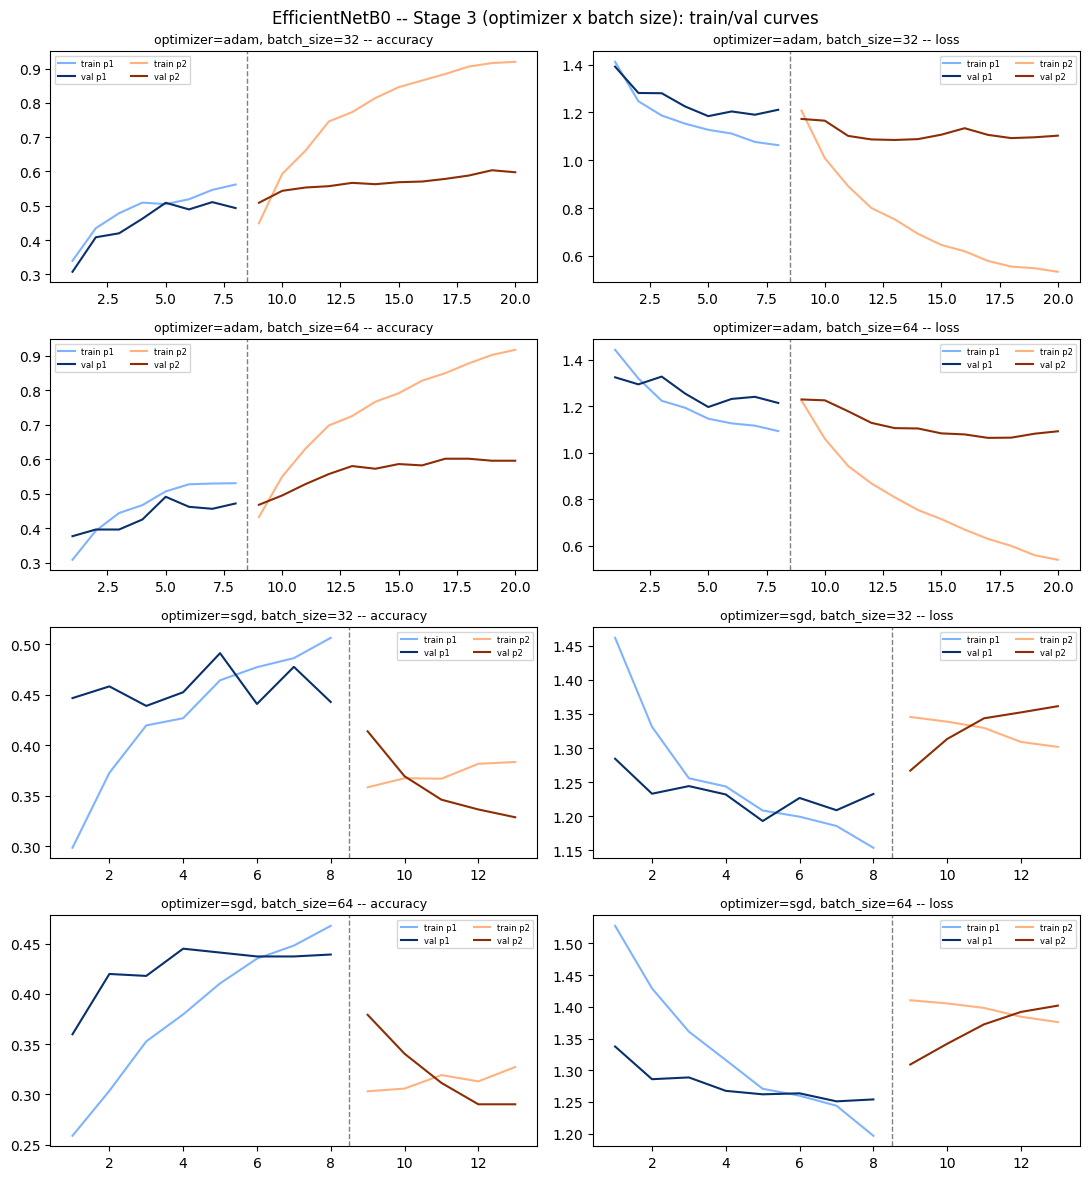

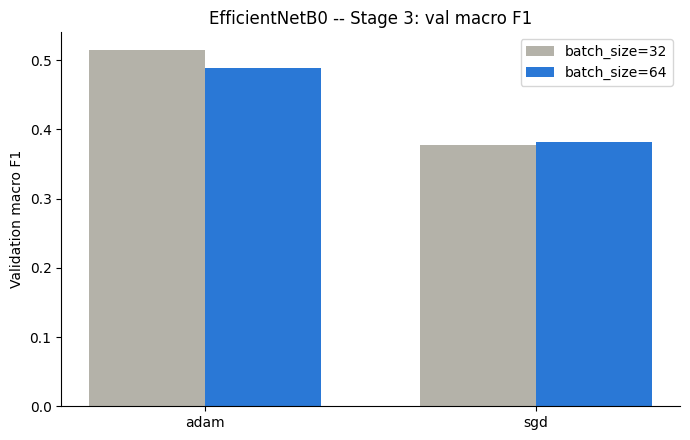

In [4]:
# ============================================================
# 8. STAGE 3 -- OPTIMIZER x BATCH SIZE GRID, on the Stage 1+2 winner. Still no test touch.
# ============================================================
optim_rows, optim_results, optim_labels = [], [], []
t_optim0 = time.time()
for optimizer_name in OPTIMIZERS:
    for bs in BATCH_SIZES_GRID:
        optim_train_ds, optim_val_ds, _optim_test_ds, optim_train_raw, OPTIM_CLASS_NAMES = build_datasets(
            DATA_VARIANTS[BEST_DATA_VARIANT], batch_size=bs)
        OPTIM_N_CLASSES = len(OPTIM_CLASS_NAMES)
        optim_class_weight = class_weight_for(optim_train_raw, OPTIM_N_CLASSES, LOSS_VARIANTS[BEST_LOSS_VARIANT])
        run_name = f"{BACKBONE_KEY}_stage3_{optimizer_name}_bs{bs}"
        label = f"optimizer={optimizer_name}, batch_size={bs}"
        print(f"\\n=== Stage 3 cell: {label} ===")
        t0 = time.time()
        result = train_two_phase(run_name, optim_train_ds, optim_val_ds, optim_class_weight, OPTIM_N_CLASSES,
                                  GRID_PHASE1_EPOCHS, GRID_PHASE2_EPOCHS, BEST_PHASE2_LR,
                                  dropout_rate=BEST_DROPOUT, weight_decay=BEST_WEIGHT_DECAY,
                                  optimizer_name=optimizer_name, early_stop_patience=GRID_EARLY_STOP_PATIENCE)
        minutes = (time.time() - t0) / 60
        val_acc, val_macro_f1, _, _, _ = evaluate_split(result["model"], optim_val_ds, OPTIM_N_CLASSES, OPTIM_CLASS_NAMES)
        print(f"{label}: val_accuracy={val_acc:.4f} val_macro_f1={val_macro_f1:.4f} "
              f"train_val_gap={result['train_val_gap']:.4f} ({result['winning_phase']}, {minutes:.1f} min)")
        free_run_memory(result)
        optim_rows.append({
            "optimizer": optimizer_name, "batch_size": bs,
            "val_accuracy": round(val_acc, 4), "val_macro_f1": round(val_macro_f1, 4),
            "train_val_gap": round(result["train_val_gap"], 4),
            "winning_phase": result["winning_phase"], "training_minutes": round(minutes, 2),
        })
        optim_results.append(result); optim_labels.append(label)

optim_df = pd.DataFrame(optim_rows)
optim_df.to_csv(OUTPUT_DIR / f"{BACKBONE_KEY}_stage3_optimizer_batchsize_grid.csv", index=False)
print(f"\\nStage 3 total time: {(time.time() - t_optim0) / 60:.1f} min")
print(optim_df.to_string(index=False))

plot_grid_curves(optim_results, optim_labels,
                  f"{BB['title']} -- Stage 3 (optimizer x batch size): train/val curves",
                  OUTPUT_DIR / f"{BACKBONE_KEY}_stage3_curves.png")

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(OPTIMIZERS)); bw = 0.35
colors3 = {BATCH_SIZES_GRID[0]: "#b4b2a9", BATCH_SIZES_GRID[1]: "#2a78d6"}
for i, bs in enumerate(BATCH_SIZES_GRID):
    vals = [optim_df[(optim_df.optimizer == o) & (optim_df.batch_size == bs)]["val_macro_f1"].iloc[0]
            for o in OPTIMIZERS]
    ax.bar(x + (i - 0.5) * bw, vals, bw, label=f"batch_size={bs}", color=colors3[bs])
ax.set_xticks(x, list(OPTIMIZERS)); ax.set_ylabel("Validation macro F1")
ax.set_title(f"{BB['title']} -- Stage 3: val macro F1")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / f"{BACKBONE_KEY}_stage3_bars.png", dpi=150, bbox_inches="tight")
plt.show()


In [5]:
# ============================================================
# 9. PICK STAGE 3 WINNER -- val macro F1 first, train/val gap as tie-break. Test untouched.
# ============================================================
_top3 = optim_df["val_macro_f1"].max()
_close3 = optim_df[optim_df["val_macro_f1"] >= _top3 - 0.01].sort_values("train_val_gap")
best_optim_row = _close3.iloc[0]
BEST_OPTIMIZER = best_optim_row["optimizer"]
BEST_BATCH_SIZE = int(best_optim_row["batch_size"])
print("Stage 3 winner (optimizer x batch size):")
print(f"  optimizer   = {BEST_OPTIMIZER}")
print(f"  batch_size  = {BEST_BATCH_SIZE}")
print(f"  val_accuracy = {best_optim_row['val_accuracy']}   val_macro_f1 = {best_optim_row['val_macro_f1']}   "
      f"train_val_gap = {best_optim_row['train_val_gap']}")
print()
print("Full ranked grid:")
print(optim_df.sort_values(['val_macro_f1', 'train_val_gap'], ascending=[False, True]).to_string(index=False))

# --- Save checkpoint for Stage 4 ---
_ckpt.update(BEST_OPTIMIZER=BEST_OPTIMIZER, BEST_BATCH_SIZE=BEST_BATCH_SIZE)
CHECKPOINT_OUTPUT.write_text(_json.dumps(_ckpt, indent=2))
print("\nSaved checkpoint for Stage 4:", _ckpt)


Stage 3 winner (optimizer x batch size):
  optimizer   = adam
  batch_size  = 32
  val_accuracy = 0.6035   val_macro_f1 = 0.5143   train_val_gap = 0.3125

Full ranked grid:
optimizer  batch_size  val_accuracy  val_macro_f1  train_val_gap       winning_phase  training_minutes
     adam          32        0.6035        0.5143         0.3125 phase2 (fine-tuned)             46.53
     adam          64        0.6015        0.4889         0.2478 phase2 (fine-tuned)             46.85
      sgd          64        0.4449        0.3810        -0.0653     phase1 (frozen)             30.27
      sgd          32        0.4913        0.3771        -0.0268     phase1 (frozen)             30.77

Saved checkpoint for Stage 4: {'BACKBONE_KEY': 'efficientnetb0', 'BEST_PHASE2_LR': 0.0001, 'BEST_DATA_VARIANT': 'augmented', 'BEST_LOSS_VARIANT': 'weighted', 'BEST_DROPOUT': 0.5, 'BEST_WEIGHT_DECAY': 0.0, 'BEST_OPTIMIZER': 'adam', 'BEST_BATCH_SIZE': 32}


## Next step

Create a Kaggle Dataset from this notebook's Output, then move to the Stage 4 notebook
(`zenodo-tune-stage4-head-architecture.ipynb`) and attach it there.
